#Data PreProcessing



In [ ]:
import yfinance as yf

ticker = yf.Ticker("BBRI.JK")
df = ticker.history(start="2019-01-01", end="2025-12-31")
df[['Open','High','Low','Close']].to_csv("BBRI_2019_2025.csv")

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, LSTM

In [ ]:
data_saham = pd.read_csv('/content/BBRI_2019_2025.csv', parse_dates=['Date'], sep=',', index_col='Date')


In [ ]:
data_saham

,Open,High,Low,Close
Date,,,,
2019-01-01 00:00:00+07:00,2286.934326,2286.934326,2286.934326,2286.934326
2019-01-02 00:00:00+07:00,2255.691650,2274.436983,2243.194818,2255.691650
2019-01-03 00:00:00+07:00,2236.946110,2274.436773,2236.946110,2261.939941
2019-01-04 00:00:00+07:00,2261.940489,2286.934326,2255.691988,2286.934326
2019-01-07 00:00:00+07:00,2311.928163,2318.176497,2286.934326,2286.934326
...,...,...,...,...
2025-12-22 00:00:00+07:00,3633.362420,3642.999986,3614.087287,3623.724854
2025-12-23 00:00:00+07:00,3623.724982,3643.000115,3594.812283,3633.362549
2025-12-24 00:00:00+07:00,3633.362549,3652.637682,3614.087416,3633.362549


Text(0.5, 1.0, 'Harga Buka Saham BBRI')

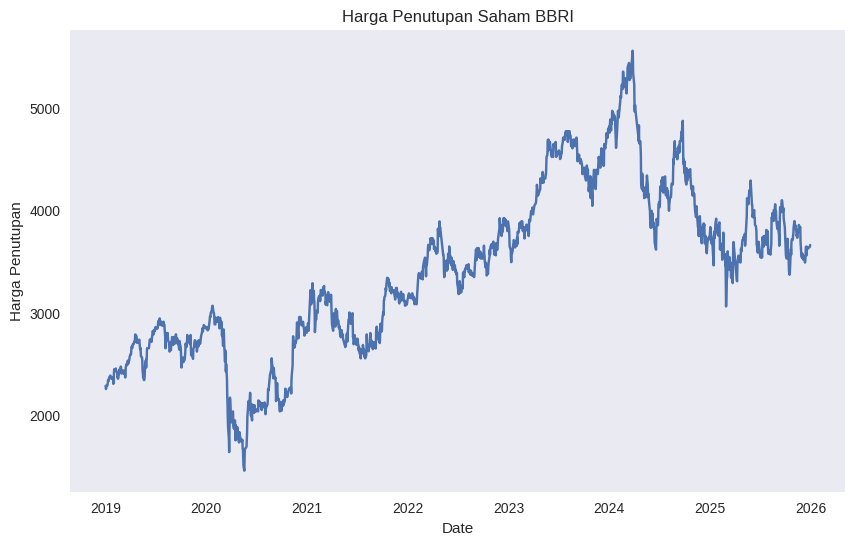

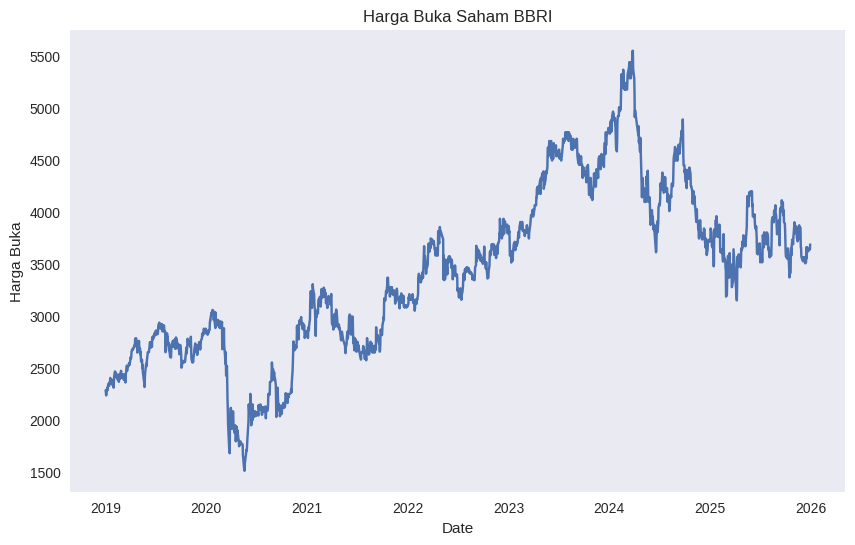

In [ ]:
#Satu Fitur
df_close = data_saham['Close']
df_open = data_saham['Open']
df_high = data_saham['High']
df_low = data_saham['Low']

#Dua Fitur
df_open_close = data_saham[['Open','Close']]
df_high_close = data_saham[['High','Close']]
df_low_close = data_saham[['Low','Close']]
df_open_high = data_saham[['Open','High']]
df_open_low = data_saham[['Open','Low']]
df_high_low = data_saham[['High','Low']]

#Tiga Fitur
df_open_high_close = data_saham[['Open','High','Close']]
df_open_low_close = data_saham[['Open','Low','Close']]
df_high_low_close = data_saham[['High','Low','Close']]
df_open_high_low = data_saham[['Open','High','Low']]

#Empat Fitur
df_open_high_low_close = data_saham[['Open','High','Low','Close']]

plt.figure(figsize=(10,6))
plt.grid()
plt.plot(df_close)
plt.xlabel('Date')
plt.ylabel('Harga Penutupan')
plt.title('Harga Penutupan Saham BBRI')

plt.figure(figsize=(10,6))
plt.grid()
plt.plot(df_open)
plt.xlabel('Date')
plt.ylabel('Harga Buka')
plt.title('Harga Buka Saham BBRI')

In [ ]:
df_open

,Open
Date,
2019-01-01 00:00:00+07:00,2286.934326
2019-01-02 00:00:00+07:00,2255.691650
2019-01-03 00:00:00+07:00,2236.946110
2019-01-04 00:00:00+07:00,2261.940489
2019-01-07 00:00:00+07:00,2311.928163
...,...
2025-12-22 00:00:00+07:00,3633.362420
2025-12-23 00:00:00+07:00,3623.724982
2025-12-24 00:00:00+07:00,3633.362549


<Figure size 800x550 with 0 Axes>

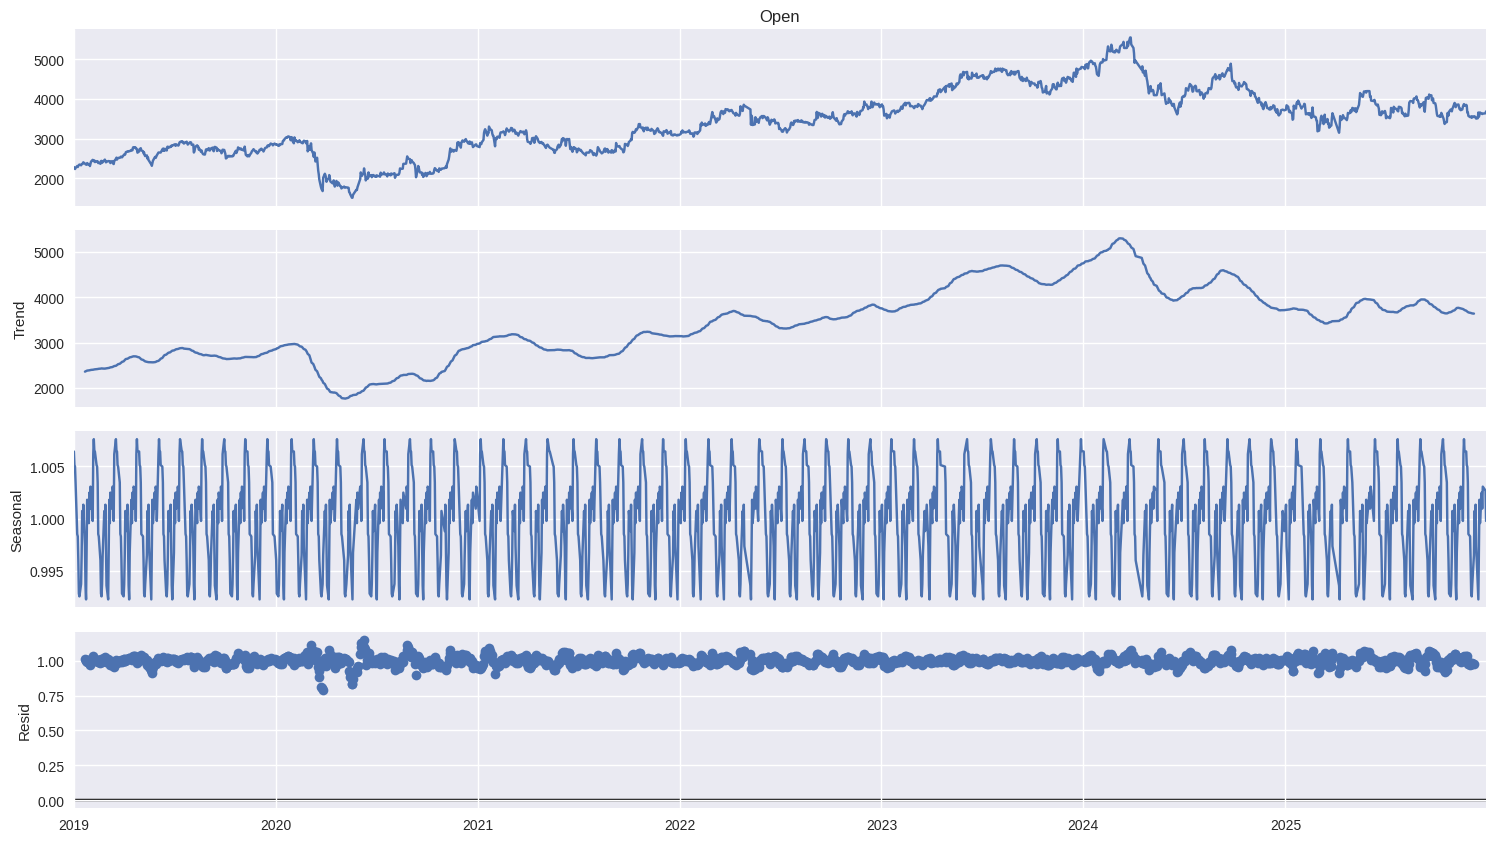

In [ ]:
#GANTI
result = seasonal_decompose(df_open, model='multiplicative',period=28)
fig = plt.figure()
fig = result.plot()
fig.set_size_inches(16, 9)

Text(0.5, 1.0, 'Transformed data')

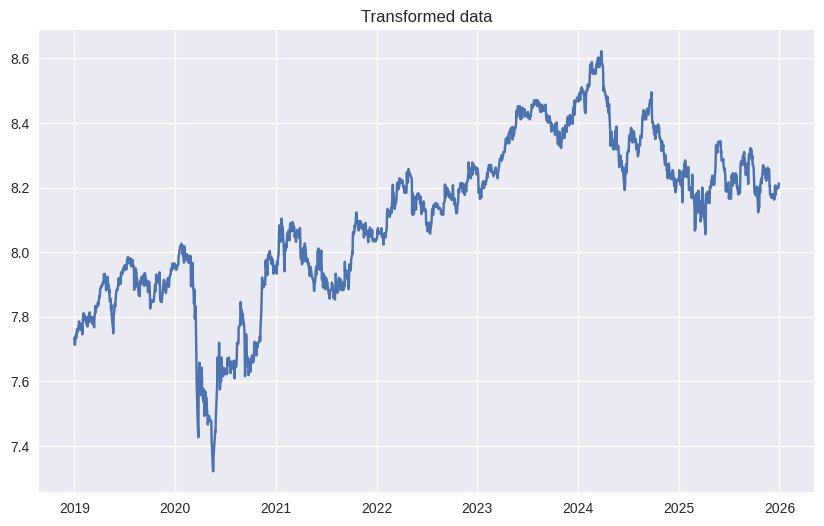

In [ ]:
#Untuk mengecilkan skala menggunakan fungsi Log tapi masih mempertahankan karakter data
df_close_log = np.log(df_close)
df_open_log = np.log(df_open)
df_high_log = np.log(df_high)
df_low_log = np.log(df_low)
df_open_close_log = np.log(df_open_close)
df_high_close_log = np.log(df_high_close)
df_low_close_log = np.log(df_low_close)
df_open_high_log = np.log(df_open_high)
df_open_low_log = np.log(df_open_low)
df_high_low_log = np.log(df_high_low)
df_open_high_close_log = np.log(df_open_high_close)
df_open_low_close_log = np.log(df_open_low_close)
df_high_low_close_log = np.log(df_high_low_close)
df_open_high_low_log = np.log(df_open_high_low)
df_open_high_low_close_log = np.log(df_open_high_low_close)

plt.figure(figsize = (10,6))
plt.plot(df_open_log)
plt.title('Transformed data')

In [ ]:
from sklearn.model_selection import train_test_split

# Mengumpulkan semua dataset
datasets = {
    "open": df_open_log,
    "high": df_high_log,
    "low": df_low_log,
    "close": df_close_log,

    "open_close": df_open_close_log,
    "open_high": df_open_high_log,
    "open_low": df_open_low_log,
    "high_low": df_high_low_log,
    "low_close": df_low_close_log,
    "high_close": df_high_close_log,

    "open_high_low": df_open_high_low_log,
    "open_low_close": df_open_low_close_log,
    "open_high_close": df_open_high_close_log,
    "high_low_close": df_high_low_close_log,

    "open_high_low_close": df_open_high_low_close_log
}

splits = {}

for name, df in datasets.items():

    # split train dan sementara (val+test)
    train, temp = train_test_split(df, test_size=0.30, shuffle=False)

    # split validation dan test
    val, test = train_test_split(temp, test_size=0.50, shuffle=False)

    splits[name] = {
        "train": train,
        "validation": val,
        "test": test
    }

# Satu fitur
train_open = splits["open"]["train"]
val_open = splits["open"]["validation"]
test_open = splits["open"]["test"]

train_high = splits["high"]["train"]
val_high = splits["high"]["validation"]
test_high = splits["high"]["test"]

train_low = splits["low"]["train"]
val_low = splits["low"]["validation"]
test_low = splits["low"]["test"]

train_close = splits["close"]["train"]
val_close = splits["close"]["validation"]
test_close = splits["close"]["test"]

# Dua Fitur
train_open_close = splits["open_close"]["train"]
val_open_close = splits["open_close"]["validation"]
test_open_close = splits["open_close"]["test"]

train_open_high = splits["open_high"]["train"]
val_open_high = splits["open_high"]["validation"]
test_open_high = splits["open_high"]["test"]

train_open_low = splits["open_low"]["train"]
val_open_low = splits["open_low"]["validation"]
test_open_low = splits["open_low"]["test"]

train_high_low = splits["high_low"]["train"]
val_high_low = splits["high_low"]["validation"]
test_high_low = splits["high_low"]["test"]

train_high_close = splits["high_close"]["train"]
val_high_close = splits["high_close"]["validation"]
test_high_close = splits["high_close"]["test"]

train_low_close = splits["low_close"]["train"]
val_low_close = splits["low_close"]["validation"]
test_low_close = splits["low_close"]["test"]

# Tiga fitur
train_open_high_low = splits["open_high_low"]["train"]
val_open_high_low = splits["open_high_low"]["validation"]
test_open_high_low = splits["open_high_low"]["test"]

train_open_high_close = splits["open_high_close"]["train"]
val_open_high_close = splits["open_high_close"]["validation"]
test_open_high_close = splits["open_high_close"]["test"]

train_open_low_close = splits["open_low_close"]["train"]
val_open_low_close = splits["open_low_close"]["validation"]
test_open_low_close = splits["open_low_close"]["test"]

train_high_low_close = splits["high_low_close"]["train"]
val_high_low_close = splits["high_low_close"]["validation"]
test_high_low_close = splits["high_low_close"]["test"]

# Empat Fitur
train_open_high_low_close = splits["open_high_low_close"]["train"]
val_open_high_low_close = splits["open_high_low_close"]["validation"]
test_open_high_low_close = splits["open_high_low_close"]["test"]

In [ ]:
train_open

,Open
Date,
2019-01-01 00:00:00+07:00,7.734967
2019-01-02 00:00:00+07:00,7.721212
2019-01-03 00:00:00+07:00,7.712867
2019-01-04 00:00:00+07:00,7.723978
2019-01-07 00:00:00+07:00,7.745837
...,...
2023-10-27 00:00:00+07:00,8.328961
2023-10-30 00:00:00+07:00,8.335004
2023-10-31 00:00:00+07:00,8.335004


In [ ]:
val_open

,Open
Date,
2023-11-03 00:00:00+07:00,8.343999
2023-11-06 00:00:00+07:00,8.358814
2023-11-07 00:00:00+07:00,8.383028
2023-11-08 00:00:00+07:00,8.378232
2023-11-09 00:00:00+07:00,8.383029
...,...
2024-11-21 00:00:00+07:00,8.235718
2024-11-22 00:00:00+07:00,8.228684
2024-11-25 00:00:00+07:00,8.267904


In [ ]:
test_open

,Open
Date,
2024-11-29 00:00:00+07:00,8.235718
2024-12-02 00:00:00+07:00,8.233378
2024-12-03 00:00:00+07:00,8.226328
2024-12-04 00:00:00+07:00,8.226328
2024-12-05 00:00:00+07:00,8.242703
...,...
2025-12-22 00:00:00+07:00,8.197914
2025-12-23 00:00:00+07:00,8.195258
2025-12-24 00:00:00+07:00,8.197914


In [ ]:
train_open_close

,Open,Close
Date,,
2019-01-01 00:00:00+07:00,7.734967,7.734967
2019-01-02 00:00:00+07:00,7.721212,7.721212
2019-01-03 00:00:00+07:00,7.712867,7.723978
2019-01-04 00:00:00+07:00,7.723978,7.734967
2019-01-07 00:00:00+07:00,7.745837,7.734967
...,...,...
2023-10-27 00:00:00+07:00,8.328961,8.339012
2023-10-30 00:00:00+07:00,8.335004,8.339012
2023-10-31 00:00:00+07:00,8.335004,8.330979


In [ ]:
# Standarisasi data MinMaxScaler

from sklearn.preprocessing import MinMaxScaler

scaled_splits = {}

for name, data in splits.items():

    train = data["train"]
    val = data["validation"]
    test = data["test"]

    scaler = MinMaxScaler()

    # Ensure the input to scaler is 2-dimensional
    # If it's a pandas Series, convert it to a DataFrame with a single column
    if isinstance(train, pd.Series):
        train = train.to_frame()
        val = val.to_frame()
        test = test.to_frame()

    # fit hanya pada train
    scaler.fit(train)

    # transform
    train_scaled = scaler.transform(train)
    val_scaled = scaler.transform(val)
    test_scaled = scaler.transform(test)

    scaled_splits[name] = {
        "train": train_scaled,
        "validation": val_scaled,
        "test": test_scaled,
        "scaler": scaler
    }

# Satu fitur
train_scaled_open = scaled_splits["open"]["train"]
val_scaled_open = scaled_splits["open"]["validation"]
test_scaled_open = scaled_splits["open"]["test"]

train_scaled_high = scaled_splits["high"]["train"]
val_scaled_high = scaled_splits["high"]["validation"]
test_scaled_high = scaled_splits["high"]["test"]

train_scaled_low = scaled_splits["low"]["train"]
val_scaled_low = scaled_splits["low"]["validation"]
test_scaled_low = scaled_splits["low"]["test"]

train_scaled_close = scaled_splits["close"]["train"]
val_scaled_close = scaled_splits["close"]["validation"]
test_scaled_close = scaled_splits["close"]["test"]

# Dua Fitur
train_scaled_open_close = scaled_splits["open_close"]["train"]
val_scaled_open_close = scaled_splits["open_close"]["validation"]
test_scaled_open_close = scaled_splits["open_close"]["test"]

train_scaled_open_high = scaled_splits["open_high"]["train"]
val_scaled_open_high = scaled_splits["open_high"]["validation"]
test_scaled_open_high = scaled_splits["open_high"]["test"]

train_scaled_open_low = scaled_splits["open_low"]["train"]
val_scaled_open_low = scaled_splits["open_low"]["validation"]
test_scaled_open_low = scaled_splits["open_low"]["test"]

train_scaled_high_low = scaled_splits["high_low"]["train"]
val_scaled_high_low = scaled_splits["high_low"]["validation"]
test_scaled_high_low = scaled_splits["high_low"]["test"]

train_scaled_high_close = scaled_splits["high_close"]["train"]
val_scaled_high_close = scaled_splits["high_close"]["validation"]
test_scaled_high_close = scaled_splits["high_close"]["test"]

train_scaled_low_close = scaled_splits["low_close"]["train"]
val_scaled_low_close = scaled_splits["low_close"]["validation"]
test_scaled_low_close = scaled_splits["low_close"]["test"]

# Tiga Fitur
train_scaled_open_high_low = scaled_splits["open_high_low"]["train"]
val_scaled_open_high_low = scaled_splits["open_high_low"]["validation"]
test_scaled_open_high_low = scaled_splits["open_high_low"]["test"]

train_scaled_open_high_close = scaled_splits["open_high_close"]["train"]
val_scaled_open_high_close = scaled_splits["open_high_close"]["validation"]
test_scaled_open_high_close = scaled_splits["open_high_close"]["test"]

train_scaled_open_low_close = scaled_splits["open_low_close"]["train"]
val_scaled_open_low_close = scaled_splits["open_low_close"]["validation"]
test_scaled_open_low_close = scaled_splits["open_low_close"]["test"]

train_scaled_high_low_close = scaled_splits["high_low_close"]["train"]
val_scaled_high_low_close = scaled_splits["high_low_close"]["validation"]
test_scaled_high_low_close = scaled_splits["high_low_close"]["test"]

# Empat Fitur
train_scaled_open_high_low_close = scaled_splits["open_high_low_close"]["train"]
val_scaled_open_high_low_close = scaled_splits["open_high_low_close"]["validation"]
test_scaled_open_high_low_close = scaled_splits["open_high_low_close"]["test"]


In [ ]:
train_scaled_close

array([[0.37947961],
       [0.36786769],
       [0.3702028 ],
       ...,
       [0.88261046],
       [0.86019013],
       [0.88939093]])

In [ ]:
test_close.shape

(256,)

In [ ]:
train_scaled_open

array([[0.35991795],
       [0.34793996],
       [0.34067331],
       ...,
       [0.88241385],
       [0.87185889],
       [0.87539146]])

In [ ]:
train_scaled_open_high_low_close

array([[0.35991795, 0.35224739, 0.38330651, 0.37947961],
       [0.34793996, 0.34747537, 0.36700788, 0.36786769],
       [0.34067331, 0.34747529, 0.36465352, 0.3702028 ],
       ...,
       [0.88241385, 0.87828657, 0.8863425 , 0.88261046],
       [0.87185889, 0.87129166, 0.8639264 , 0.86019013],
       [0.87539146, 0.89125251, 0.87779124, 0.88939093]])

In [ ]:
train_scaled_open_high_low_close[1]

array([0.34793996, 0.34747537, 0.36700788, 0.36786769])

In [ ]:
#GANTI
# Pembentukan Sequence untuk target / y_train (harga pembukaan)

y_open_train = scaled_splits["open"]["train"]

import numpy as np

def create_sequences(features, target, seq_length=7):

    X = []
    y = []

    for i in range(len(features) - seq_length):
        X.append(features[i:i+seq_length])
        y.append(target[i+seq_length])

    return np.array(X), np.array(y)

In [ ]:
#GANTI
# Pembentukan Sequence untuk X_train

train_sequences = {}

for name, data in scaled_splits.items():

    X_data = data["train"]

    X_train, y_train = create_sequences(
        X_data,
        y_open_train,
        seq_length=7
    )

    train_sequences[name] = {
        "X_train": X_train,
        "y_train": y_train
    }

In [ ]:
# Shape sequence train

for name in train_sequences:

    print(name)
    print("X_train:", train_sequences[name]["X_train"].shape)
    print("y_train:", train_sequences[name]["y_train"].shape)
    print()

open
X_train: (1186, 7, 1)
y_train: (1186, 1)

high
X_train: (1186, 7, 1)
y_train: (1186, 1)

low
X_train: (1186, 7, 1)
y_train: (1186, 1)

close
X_train: (1186, 7, 1)
y_train: (1186, 1)

open_close
X_train: (1186, 7, 2)
y_train: (1186, 1)

open_high
X_train: (1186, 7, 2)
y_train: (1186, 1)

open_low
X_train: (1186, 7, 2)
y_train: (1186, 1)

high_low
X_train: (1186, 7, 2)
y_train: (1186, 1)

low_close
X_train: (1186, 7, 2)
y_train: (1186, 1)

high_close
X_train: (1186, 7, 2)
y_train: (1186, 1)

open_high_low
X_train: (1186, 7, 3)
y_train: (1186, 1)

open_low_close
X_train: (1186, 7, 3)
y_train: (1186, 1)

open_high_close
X_train: (1186, 7, 3)
y_train: (1186, 1)

high_low_close
X_train: (1186, 7, 3)
y_train: (1186, 1)

open_high_low_close
X_train: (1186, 7, 4)
y_train: (1186, 1)



In [ ]:
# Data siap pakai train

# Satu fitur
X_train_open = train_sequences["open"]["X_train"]
y_train_open = train_sequences["open"]["y_train"]

X_train_high = train_sequences["high"]["X_train"]
y_train_high = train_sequences["high"]["y_train"]

X_train_low = train_sequences["low"]["X_train"]
y_train_low = train_sequences["low"]["y_train"]

X_train_close = train_sequences["close"]["X_train"]
y_train_close = train_sequences["close"]["y_train"]

# Dua Fitur
X_train_open_high = train_sequences["open_high"]["X_train"]
y_train_open_high = train_sequences["open_high"]["y_train"]

X_train_open_low = train_sequences["open_low"]["X_train"]
y_train_open_low = train_sequences["open_low"]["y_train"]

X_train_high_low = train_sequences["high_low"]["X_train"]
y_train_high_low = train_sequences["high_low"]["y_train"]

X_train_open_close = train_sequences["open_close"]["X_train"]
y_train_open_close = train_sequences["open_close"]["y_train"]

X_train_high_close = train_sequences["high_close"]["X_train"]
y_train_high_close = train_sequences["high_close"]["y_train"]

X_train_low_close = train_sequences["low_close"]["X_train"]
y_train_low_close = train_sequences["low_close"]["y_train"]

# Tiga Fitur
X_train_open_high_low = train_sequences["open_high_low"]["X_train"]
y_train_open_high_low = train_sequences["open_high_low"]["y_train"]

X_train_open_high_close = train_sequences["open_high_close"]["X_train"]
y_train_open_high_close = train_sequences["open_high_close"]["y_train"]

X_train_open_low_close = train_sequences["open_low_close"]["X_train"]
y_train_open_low_close = train_sequences["open_low_close"]["y_train"]

X_train_high_low_close = train_sequences["high_low_close"]["X_train"]
y_train_high_low_close = train_sequences["high_low_close"]["y_train"]

# Empat Fitur
X_train_open_high_low_close = train_sequences["open_high_low_close"]["X_train"]
y_train_open_high_low_close = train_sequences["open_high_low_close"]["y_train"]


In [ ]:
X_train_open[0]

array([[0.35991795],
       [0.34793996],
       [0.34067331],
       [0.35034889],
       [0.36938298],
       [0.35991785],
       [0.37173286]])

In [ ]:
X_train_open[1]

array([[0.34793996],
       [0.34067331],
       [0.35034889],
       [0.36938298],
       [0.35991785],
       [0.37173286],
       [0.37874603]])

In [ ]:
y_train_open[0]

array([0.37874603])

In [ ]:
X_train_open_high_low_close[0]

array([[0.35991795, 0.35224739, 0.38330651, 0.37947961],
       [0.34793996, 0.34747537, 0.36700788, 0.36786769],
       [0.34067331, 0.34747529, 0.36465352, 0.3702028 ],
       [0.35034889, 0.35224739, 0.3716969 , 0.37947961],
       [0.36938298, 0.36406385, 0.38330651, 0.37947961],
       [0.35991785, 0.35699312, 0.37635986, 0.38407984],
       [0.37173286, 0.37107719, 0.39019602, 0.39320578]])

In [ ]:
X_train_open_high_low_close[1]

array([[0.34793996, 0.34747537, 0.36700788, 0.36786769],
       [0.34067331, 0.34747529, 0.36465352, 0.3702028 ],
       [0.35034889, 0.35224739, 0.3716969 , 0.37947961],
       [0.36938298, 0.36406385, 0.38330651, 0.37947961],
       [0.35991785, 0.35699312, 0.37635986, 0.38407984],
       [0.37173286, 0.37107719, 0.39019602, 0.39320578],
       [0.37874603, 0.3734028 , 0.39475837, 0.39998641]])

In [ ]:
y_train

array([[0.37874603],
       [0.38339021],
       [0.37641462],
       ...,
       [0.88241385],
       [0.87185889],
       [0.87539146]])

In [ ]:
print(X_train_open.shape)
print(y_train_open.shape)

print(X_train_open_high_low_close.shape)
print(y_train_open_high_low_close.shape)

(1186, 7, 1)
(1186, 1)
(1186, 7, 4)
(1186, 1)


In [ ]:
#GANTI
# Pembentukan Sequnce data Validation dan data test

y_open_val = scaled_splits["open"]["validation"]
y_open_test = scaled_splits["open"]["test"]

val_sequences = {}
test_sequences = {}

for name, data in scaled_splits.items():

    val_data = data["validation"]
    test_data = data["test"]

    X_val, y_val = create_sequences(val_data, y_open_val, seq_length=7)
    X_test, y_test = create_sequences(test_data, y_open_test, seq_length=7)

    val_sequences[name] = {
        "X_val": X_val,
        "y_val": y_val
    }

    test_sequences[name] = {
        "X_test": X_test,
        "y_test": y_test
    }

In [ ]:
# Shape sequence validation

for name in val_sequences:

    print(name)
    print("X_val:", val_sequences[name]["X_val"].shape)
    print("y_val:", val_sequences[name]["y_val"].shape)
    print()

open
X_val: (249, 7, 1)
y_val: (249, 1)

high
X_val: (249, 7, 1)
y_val: (249, 1)

low
X_val: (249, 7, 1)
y_val: (249, 1)

close
X_val: (249, 7, 1)
y_val: (249, 1)

open_close
X_val: (249, 7, 2)
y_val: (249, 1)

open_high
X_val: (249, 7, 2)
y_val: (249, 1)

open_low
X_val: (249, 7, 2)
y_val: (249, 1)

high_low
X_val: (249, 7, 2)
y_val: (249, 1)

low_close
X_val: (249, 7, 2)
y_val: (249, 1)

high_close
X_val: (249, 7, 2)
y_val: (249, 1)

open_high_low
X_val: (249, 7, 3)
y_val: (249, 1)

open_low_close
X_val: (249, 7, 3)
y_val: (249, 1)

open_high_close
X_val: (249, 7, 3)
y_val: (249, 1)

high_low_close
X_val: (249, 7, 3)
y_val: (249, 1)

open_high_low_close
X_val: (249, 7, 4)
y_val: (249, 1)



In [ ]:
# Shape sequence test

for name in val_sequences:

    print(name)
    print("X_test:", test_sequences[name]["X_test"].shape)
    print("y_test:", test_sequences[name]["y_test"].shape)
    print()

open
X_test: (249, 7, 1)
y_test: (249, 1)

high
X_test: (249, 7, 1)
y_test: (249, 1)

low
X_test: (249, 7, 1)
y_test: (249, 1)

close
X_test: (249, 7, 1)
y_test: (249, 1)

open_close
X_test: (249, 7, 2)
y_test: (249, 1)

open_high
X_test: (249, 7, 2)
y_test: (249, 1)

open_low
X_test: (249, 7, 2)
y_test: (249, 1)

high_low
X_test: (249, 7, 2)
y_test: (249, 1)

low_close
X_test: (249, 7, 2)
y_test: (249, 1)

high_close
X_test: (249, 7, 2)
y_test: (249, 1)

open_high_low
X_test: (249, 7, 3)
y_test: (249, 1)

open_low_close
X_test: (249, 7, 3)
y_test: (249, 1)

open_high_close
X_test: (249, 7, 3)
y_test: (249, 1)

high_low_close
X_test: (249, 7, 3)
y_test: (249, 1)

open_high_low_close
X_test: (249, 7, 4)
y_test: (249, 1)



In [ ]:
# Data Siap Pakai validation

# Satu Fitur
X_val_open = val_sequences["open"]["X_val"]
y_val_open = val_sequences["open"]["y_val"]

X_val_high = val_sequences["high"]["X_val"]
y_val_high = val_sequences["high"]["y_val"]

X_val_low = val_sequences["low"]["X_val"]
y_val_low = val_sequences["low"]["y_val"]

X_val_close = val_sequences["close"]["X_val"]
y_val_close = val_sequences["close"]["y_val"]

# Dua Fitur
X_val_open_high = val_sequences["open_high"]["X_val"]
y_val_open_high = val_sequences["open_high"]["y_val"]

X_val_open_low = val_sequences["open_low"]["X_val"]
y_val_open_low = val_sequences["open_low"]["y_val"]

X_val_high_low = val_sequences["high_low"]["X_val"]
y_val_high_low = val_sequences["high_low"]["y_val"]

X_val_open_close = val_sequences["open_close"]["X_val"]
y_val_open_close = val_sequences["open_close"]["y_val"]

X_val_high_close = val_sequences["high_close"]["X_val"]
y_val_high_close = val_sequences["high_close"]["y_val"]

X_val_low_close = val_sequences["low_close"]["X_val"]
y_val_low_close = val_sequences["low_close"]["y_val"]

# Tiga Fitur
X_val_open_high_low = val_sequences["open_high_low"]["X_val"]
y_val_open_high_low = val_sequences["open_high_low"]["y_val"]

X_val_open_high_close = val_sequences["open_high_close"]["X_val"]
y_val_open_high_close = val_sequences["open_high_close"]["y_val"]

X_val_open_low_close = val_sequences["open_low_close"]["X_val"]
y_val_open_low_close = val_sequences["open_low_close"]["y_val"]

X_val_high_low_close = val_sequences["high_low_close"]["X_val"]
y_val_high_low_close = val_sequences["high_low_close"]["y_val"]

# Empat Fitur
X_val_open_high_low_close = val_sequences["open_high_low_close"]["X_val"]
y_val_open_high_low_close = val_sequences["open_high_low_close"]["y_val"]


In [ ]:
X_val_open[0]

array([[0.890247  ],
       [0.90314763],
       [0.92423265],
       [0.92005633],
       [0.92423278],
       [0.91164299],
       [0.8988686 ]])

In [ ]:
X_val_open[1]

array([[0.90314763],
       [0.92423265],
       [0.92005633],
       [0.92423278],
       [0.91164299],
       [0.8988686 ],
       [0.89886857]])

In [ ]:
y_val_open[0]

array([0.89886857])

In [ ]:
X_val_open_high_low_close[0]

array([[0.890247  , 0.90824552, 0.89733123, 0.9061076 ],
       [0.90314763, 0.91244248, 0.90983524, 0.92249964],
       [0.92423265, 0.92491314, 0.92215655, 0.93057769],
       [0.92005633, 0.92077609, 0.92215661, 0.92654833],
       [0.92423278, 0.92491327, 0.92622417, 0.92249964],
       [0.91164299, 0.90402822, 0.90151981, 0.90195934],
       [0.8988686 , 0.89979048, 0.89733123, 0.89360126]])

In [ ]:
y_val_open_high_low_close[0]

array([0.89886857])

In [ ]:
# Data Siap pakai test

# Satu Fitur
X_test_open = test_sequences["open"]["X_test"]
y_test_open = test_sequences["open"]["y_test"]

X_test_high = test_sequences["high"]["X_test"]
y_test_high = test_sequences["high"]["y_test"]

X_test_low = test_sequences["low"]["X_test"]
y_test_low = test_sequences["low"]["y_test"]

X_test_close = test_sequences["close"]["X_test"]
y_test_close = test_sequences["close"]["y_test"]

# Dua Fitur
X_test_open_high = test_sequences["open_high"]["X_test"]
y_test_open_high = test_sequences["open_high"]["y_test"]

X_test_open_low = test_sequences["open_low"]["X_test"]
y_test_open_low = test_sequences["open_low" ]["y_test"]

X_test_high_low = test_sequences["high_low"]["X_test"]
y_test_high_low = test_sequences["high_low"]["y_test"]

X_test_open_close = test_sequences["open_close"]["X_test"]
y_test_open_close = test_sequences["open_close"]["y_test"]

X_test_high_close = test_sequences["high_close"]["X_test"]
y_test_high_close = test_sequences["high_close"]["y_test"]

X_test_low_close = test_sequences["low_close"]["X_test"]
y_test_low_close = test_sequences["low_close"]["y_test"]

# Tiga Fitur
X_test_open_high_low = test_sequences["open_high_low"]["X_test"]
y_test_open_high_low = test_sequences["open_high_low"]["y_test"]

X_test_open_high_close = test_sequences["open_high_close"]["X_test"]
y_test_open_high_close = test_sequences["open_high_close"]["y_test"]

X_test_open_low_close = test_sequences["open_low_close"]["X_test"]
y_test_open_low_close = test_sequences["open_low_close"]["y_test"]

X_test_high_low_close = test_sequences["high_low_close"]["X_test"]
y_test_high_low_close = test_sequences["high_low_close"]["y_test"]

# Empat fitur
X_test_open_high_low_close = test_sequences["open_high_low_close"]["X_test"]
y_test_open_high_low_close = test_sequences["open_high_low_close"]["y_test"]

In [ ]:
X_test_open[0]

array([[0.79595833],
       [0.79392139],
       [0.787782  ],
       [0.787782  ],
       [0.80204058],
       [0.78983324],
       [0.8020406 ]])

In [ ]:
y_test_open[0]

array([0.81208429])

In [ ]:
X_test_open_high_low_close[0]

array([[0.79595833, 0.79239184, 0.80000461, 0.79625629],
       [0.79392139, 0.78833183, 0.7819396 , 0.78021467],
       [0.787782  , 0.78220622, 0.79202344, 0.7942677 ],
       [0.787782  , 0.80645452, 0.79402582, 0.81588886],
       [0.80204058, 0.80045542, 0.80000459, 0.7982402 ],
       [0.78983324, 0.79441471, 0.79402577, 0.80809049],
       [0.8020406 , 0.81043106, 0.8098761 , 0.8236158 ]])

In [ ]:
y_test_open_high_low_close[0]

array([0.81208429])

In [ ]:
X_test_close[0]

array([[0.79625629],
       [0.78021467],
       [0.7942677 ],
       [0.81588886],
       [0.7982402 ],
       [0.80809049],
       [0.8236158 ]])

In [ ]:
y_test_close[0]

array([0.81208429])

#LSTM Package

In [ ]:
# Membangun model
def build_lstm_model(input_shape):

    model = Sequential()

    # Layer pertama dengan 64 neuron atau hidden unit berbentuk vektor 64 x 1
    model.add(LSTM(64, return_sequences=True, input_shape=input_shape))
    model.add(Dropout(0.2))

    # Layer kedua dengan 32 neuron atau hidden unit berbentuk vektor 32 x 1
    model.add(LSTM(32))
    model.add(Dropout(0.2))

    # Output layer 1 x 1
    model.add(Dense(1))

    model.compile(
        optimizer="adam",
        loss="mse"
    )

    return model

In [ ]:
# Training model

from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

models = {}
history_all = {}

for name in train_sequences:

    print("Training model:", name)

    X_train = train_sequences[name]["X_train"]
    y_train = train_sequences[name]["y_train"]

    X_val = val_sequences[name]["X_val"]
    y_val = val_sequences[name]["y_val"]

    input_shape = (X_train.shape[1], X_train.shape[2])

    model = build_lstm_model(input_shape)

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=100,
        verbose=1,
        callbacks=[early_stop]
    )

    models[name] = model
    history_all[name] = history

Training model: open
Epoch 1/100


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


38/38 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0954 - val_loss: 0.0378
Epoch 2/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0088 - val_loss: 0.0042
Epoch 3/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0067 - val_loss: 0.0014
Epoch 4/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0059 - val_loss: 0.0023
Epoch 5/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0053 - val_loss: 0.0013
Epoch 6/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0057 - val_loss: 0.0011
Epoch 7/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0053 - val_loss: 9.6351e-04
Epoch 8/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0051 - val_loss: 0.0010
Epoch 9/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0051 - val_loss: 0.0033
Epoch 10/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0057 - val_loss: 8.5630e-04
Epoch 11/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0047 - val_loss: 0.0024
Epoch 12/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0049

In [ ]:
# mengambil model

# Satu Fitur
model_open = models["open"]
model_high = models["high"]
model_low = models["low"]
model_close = models["close"]

# Dua Fitur
model_open_high = models["open_high"]
model_open_low = models["open_low"]
model_high_low = models["high_low"]
model_open_close = models["open_close"]
model_high_close = models["high_close"]
model_low_close = models["low_close"]

# Tiga Fitur
model_open_high_low = models["open_high_low"]
model_open_high_close = models["open_high_close"]
model_open_low_close = models["open_low_close"]
model_high_low_close = models["high_low_close"]

# Empat Fitur
model_open_high_low_close = models["open_high_low_close"]

In [ ]:
# Prediksi menggunakan model

# satu fitur
X_test_open = test_sequences["open"]["X_test"]
y_pred_open = models["open"].predict(X_test_open)

X_test_high = test_sequences["high"]["X_test"]
y_pred_high = models["high"].predict(X_test_high)

X_test_low = test_sequences["low"]["X_test"]
y_pred_low = models["low"].predict(X_test_low)

X_test_close = test_sequences["close"]["X_test"]
y_pred_close = models["close"].predict(X_test_close)

# Dua Fitur
X_test_open_high = test_sequences["open_high"]["X_test"]
y_pred_open_high = models["open_high"].predict(X_test_open_high)

X_test_open_low = test_sequences["open_low"]["X_test"]
y_pred_open_low = models["open_low"].predict(X_test_open_low)

X_test_high_low = test_sequences["high_low"]["X_test"]
y_pred_high_low = models["high_low"].predict(X_test_high_low)

X_test_open_close = test_sequences["open_close"]["X_test"]
y_pred_open_close = models["open_close"].predict(X_test_open_close)

X_test_high_close = test_sequences["high_close"]["X_test"]
y_pred_high_close = models["high_close"].predict(X_test_high_close)

X_test_low_close = test_sequences["low_close"]["X_test"]
y_pred_low_close = models["low_close"].predict(X_test_low_close)

# Tiga Fitur
X_test_open_high_low = test_sequences["open_high_low"]["X_test"]
y_pred_open_high_low = models["open_high_low"].predict(X_test_open_high_low)

X_test_open_high_close = test_sequences["open_high_close"]["X_test"]
y_pred_open_high_close = models["open_high_close"].predict(X_test_open_high_close)

X_test_open_low_close = test_sequences["open_low_close"]["X_test"]
y_pred_open_low_close = models["open_low_close"].predict(X_test_open_low_close)

X_test_high_low_close = test_sequences["high_low_close"]["X_test"]
y_pred_high_low_close = models["high_low_close"].predict(X_test_high_low_close)

# Empat fitur
X_test_open_high_low_close = test_sequences["open_high_low_close"]["X_test"]
y_pred_open_high_low_close = models["open_high_low_close"].predict(X_test_open_high_low_close)

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


In [ ]:
# struktur model

models["open"].summary()

models["open_close"].summary()

models["open_high_close"].summary()

models["open_high_low_close"].summary()

Model: "sequential_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_30 (LSTM)                  │ (None, 7, 64)          │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_30 (Dropout)            │ (None, 7, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_31 (LSTM)                  │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_31 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 88,037 (343.90 KB)

 Trainable params: 29,345 (114.63 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 58,692 (229.27 KB)

... (14 outputs left out)

 Total params: 90,341 (352.90 KB)

 Trainable params: 30,113 (117.63 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 60,228 (235.27 KB)

In [ ]:
X_test_open.shape

(249, 7, 1)

In [ ]:
y_pred_open.shape

(249, 1)

In [ ]:
X_test_open_high_low_close.shape

(249, 7, 4)

In [ ]:
y_pred_open_high_low_close.shape

(249, 1)

In [ ]:
y_test_open[0]

array([0.81208429])

In [ ]:
y_pred_open[0]

array([0.7903666], dtype=float32)

In [ ]:
y_test_open_high_low_close[0]

array([0.81208429])

In [ ]:
y_pred_open_high_low_close[0]

array([0.7809652], dtype=float32)

In [ ]:
#GANTI
import pandas as pd

# Get the original dates corresponding to the y_test data
test_dates = test_open.index[7:]

results_df = pd.DataFrame({
    "date": test_dates,
    "pred_open": y_pred_open.flatten(),
    "pred_high": y_pred_high.flatten(),
    "pred_low": y_pred_low.flatten(),
    "pred_close": y_pred_close.flatten(),

    "pred_open_high": y_pred_open_high.flatten(),
    "pred_open_low": y_pred_open_low.flatten(),
    "pred_open_close": y_pred_open_close.flatten(),

    "pred_high_low": y_pred_high_low.flatten(),
    "pred_high_close": y_pred_high_close.flatten(),
    "pred_low_close": y_pred_low_close.flatten(),

    "pred_open_high_low": y_pred_open_high_low.flatten(),
    "pred_open_high_close": y_pred_open_high_close.flatten(),
    "pred_open_low_close": y_pred_open_low_close.flatten(),

    "pred_high_low_close": y_pred_high_low_close.flatten(),

    "pred_open_high_low_close": y_pred_open_high_low_close.flatten(),

    "actual_open": y_test.flatten()
})


In [ ]:
tabel_perbandingan = results_df.set_index("date")
tabel_perbandingan

,pred_open,pred_high,pred_low,pred_close,pred_open_high,pred_open_low,pred_open_close,pred_high_low,pred_high_close,pred_low_close,pred_open_high_low,pred_open_high_close,pred_open_low_close,pred_high_low_close,pred_open_high_low_close,actual_open
date,,,,,,,,,,,,,,,,
2024-12-10 00:00:00+07:00,0.790367,0.713189,0.790390,0.660065,0.762856,0.729571,0.712002,0.715283,0.765339,0.794650,0.800000,0.713301,0.772773,0.804791,0.780965,0.812084
2024-12-11 00:00:00+07:00,0.791934,0.714801,0.791416,0.662211,0.763942,0.730371,0.713596,0.716518,0.767341,0.797364,0.801327,0.714951,0.774243,0.806587,0.783048,0.808081
2024-12-12 00:00:00+07:00,0.794337,0.717507,0.796240,0.666221,0.765960,0.732969,0.716768,0.719548,0.770924,0.802852,0.804103,0.717690,0.777649,0.810476,0.786800,0.808081
2024-12-13 00:00:00+07:00,0.797701,0.720566,0.799079,0.668058,0.768950,0.735132,0.718828,0.722211,0.773770,0.805324,0.806940,0.720260,0.779634,0.813163,0.789280,0.785726
2024-12-16 00:00:00+07:00,0.799255,0.720089,0.799999,0.666484,0.769659,0.736039,0.718365,0.722092,0.772642,0.803787,0.807269,0.719844,0.779279,0.812333,0.788366,0.769100
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-12-22 00:00:00+07:00,0.745527,0.683964,0.741958,0.632981,0.730097,0.696056,0.682423,0.683556,0.733468,0.749189,0.765074,0.683501,0.739735,0.770829,0.742641,0.763040
2025-12-23 00:00:00+07:00,0.749354,0.686791,0.748588,0.636487,0.732937,0.699795,0.685684,0.687130,0.736947,0.755005,0.768518,0.686476,0.743659,0.774916,0.746654,0.760727
2025-12-24 00:00:00+07:00,0.754068,0.690709,0.755017,0.639696,0.737348,0.703884,0.689258,0.691399,0.741158,0.760201,0.772761,0.690148,0.747643,0.779363,0.750958,0.763040


In [ ]:
len(X_test_open)

249

In [ ]:
y_train_open[0]

array([0.37874603])

# RESTORE NEW

In [ ]:
def restore_prediction(pred, scaler):

    pred_log = scaler.inverse_transform(pred.reshape(-1,1)).flatten()
    pred_original = np.exp(pred_log)

    return pred_original.flatten()

In [ ]:
#GANTI
scaler_open = scaled_splits["open"]["scaler"]

In [ ]:
#GANTI
predictions = {
    "pred_open": y_pred_open,
    "pred_high": y_pred_high,
    "pred_low": y_pred_low,
    "pred_close": y_pred_close,
    "pred_open_high": y_pred_open_high,
    "pred_open_low": y_pred_open_low,
    "pred_open_close": y_pred_open_close,
    "pred_high_low": y_pred_high_low,
    "pred_high_close": y_pred_high_close,
    "pred_low_close": y_pred_low_close,
    "pred_open_high_low": y_pred_open_high_low,
    "pred_open_high_close": y_pred_open_high_close,
    "pred_open_low_close": y_pred_open_low_close,
    "pred_high_low_close": y_pred_high_low_close,
    "pred_open_high_low_close": y_pred_open_high_low_close
}

predictions_original = {}

for name, pred in predictions.items():

    predictions_original[name] = restore_prediction(
        pred,
        scaler_open
    )

In [ ]:
for name, values in predictions_original.items():
    results_df[name] = values

In [ ]:
#GANTI
results_df["actual_open"] = actual_open = data_saham["Open"].tail(249).values

In [ ]:
results_df

,date,pred_open,pred_high,pred_low,pred_close,pred_open_high,pred_open_low,pred_open_close,pred_high_low,pred_high_close,pred_low_close,pred_open_high_low,pred_open_high_close,pred_open_low_close,pred_high_low_close,pred_open_high_low_close,actual_open
0,2024-12-10 00:00:00+07:00,3749.196045,3431.198975,3749.296143,3228.124512,3632.594238,3496.358154,3426.526123,3439.461426,3642.967773,3767.680420,3790.902100,3431.644043,3674.205566,3811.816162,3708.935547,3843.877197
1,2024-12-11 00:00:00+07:00,3755.945312,3437.559814,3753.714600,3236.092285,3637.132080,3499.574219,3432.799805,3444.342529,3651.353516,3779.441162,3796.683838,3438.153076,3680.409180,3819.687012,3717.817139,3826.244352
2,2024-12-12 00:00:00+07:00,3766.329590,3448.257080,3774.567627,3251.029785,3645.570557,3510.032715,3445.331299,3456.346191,3666.406494,3803.337646,3808.807373,3448.983887,3694.831299,3836.784424,3733.870605,3826.244451
3,2024-12-13 00:00:00+07:00,3780.904785,3460.393311,3786.895020,3257.895264,3658.108398,3518.760498,3453.489502,3466.933838,3678.412354,3814.150391,3821.239258,3459.175781,3703.269531,3848.639648,3744.518555,3729.265795
4,2024-12-16 00:00:00+07:00,3787.660645,3458.496094,3790.894775,3252.010010,3661.084961,3522.426514,3451.656006,3466.460938,3673.651611,3807.423584,3822.678955,3457.523438,3701.758545,3844.974609,3740.588867,3658.736121
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
244,2025-12-22 00:00:00+07:00,3561.019287,3317.953125,3546.456299,3129.265137,3498.476318,3364.349121,3312.088623,3316.396973,3512.044922,3576.027588,3641.862793,3316.187744,3537.413574,3666.011719,3549.237549,3633.362420
245,2025-12-23 00:00:00+07:00,3576.702637,3328.738525,3573.559082,3141.893066,3509.905762,3378.824707,3324.512939,3330.037109,3526.103271,3599.990234,3656.291016,3327.535645,3553.389893,3683.260254,3565.634033,3623.724982
246,2025-12-24 00:00:00+07:00,3596.119385,3343.752930,3600.041504,3153.492432,3527.731445,3394.728516,3338.186523,3346.400879,3543.200928,3621.535889,3674.152588,3341.597656,3569.686279,3702.114990,3583.302246,3633.362549
247,2025-12-29 00:00:00+07:00,3612.581055,3341.540527,3618.804932,3152.951172,3534.706055,3407.085938,3342.410889,3349.862061,3541.339111,3629.429443,3681.019775,3343.226807,3577.408936,3704.163330,3588.784424,3643.000000


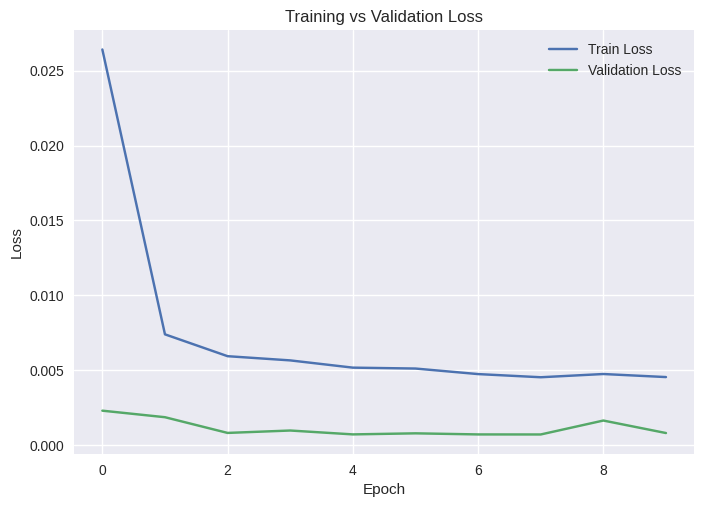

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("Training vs Validation Loss")
plt.show()

#GRAFIK PERBANDINGAN

In [ ]:
prediction_columns = [
    'pred_open',
    'pred_high',
    'pred_low',
    'pred_close',
    'pred_open_high',
    'pred_open_low',
    'pred_open_close',
    'pred_high_low',
    'pred_high_close',
    'pred_low_close',
    'pred_open_high_low',
    'pred_open_high_close',
    'pred_open_low_close',
    'pred_high_low_close',
    'pred_open_high_low_close'
]

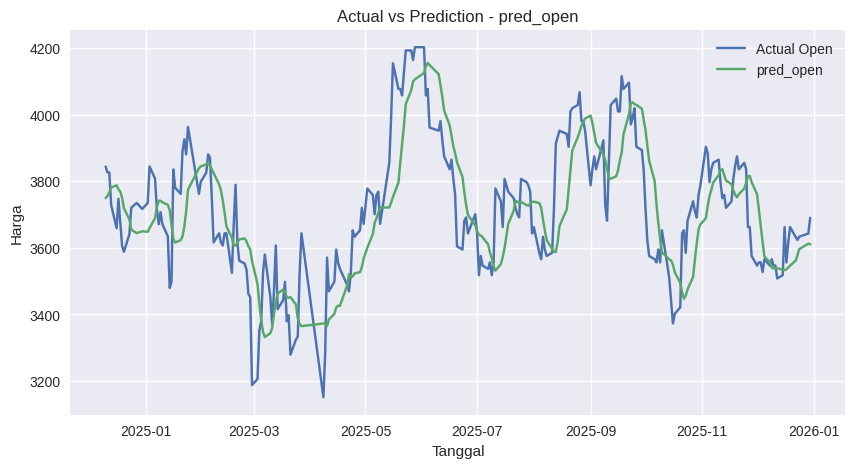

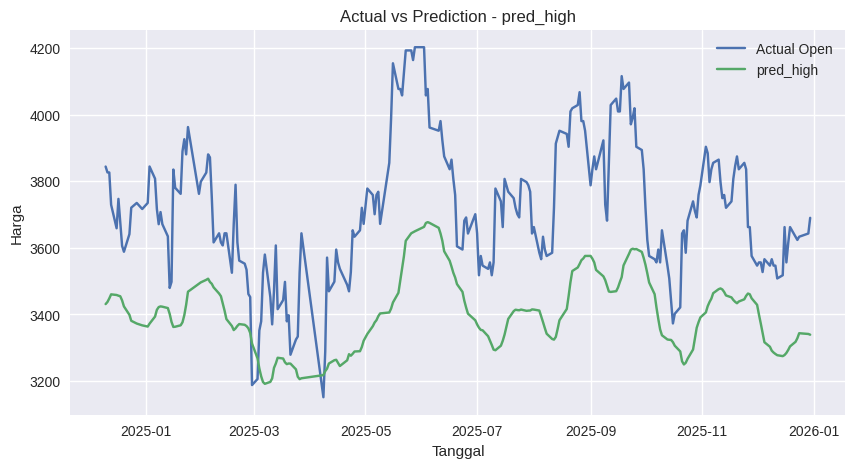

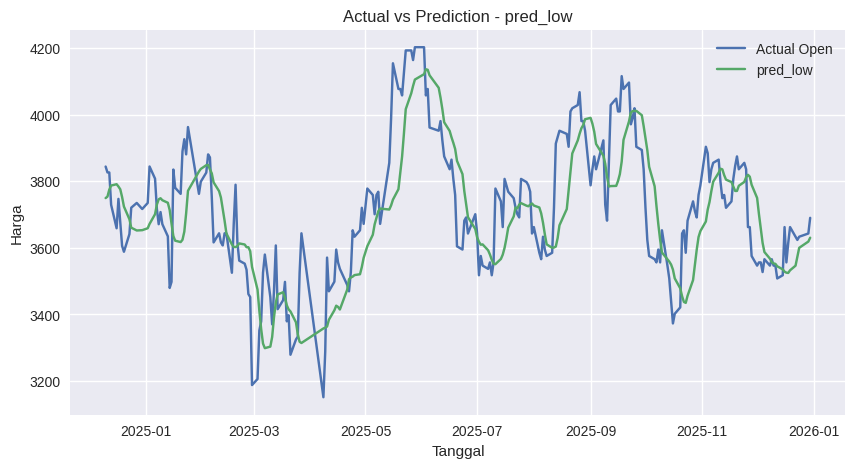

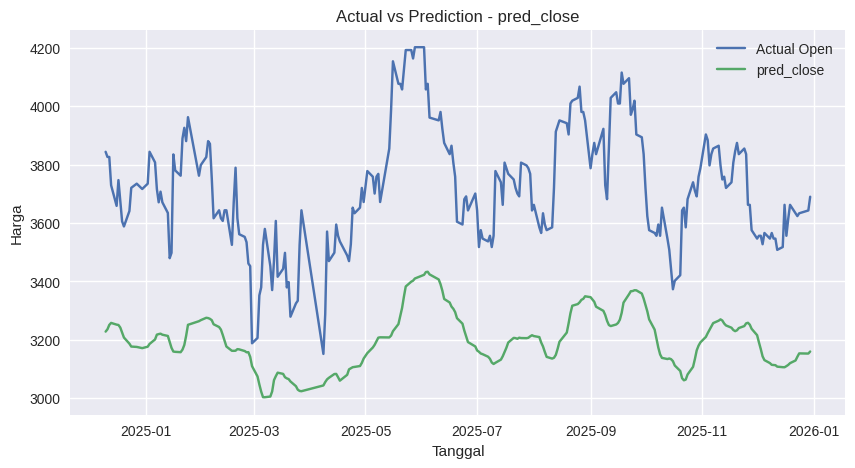

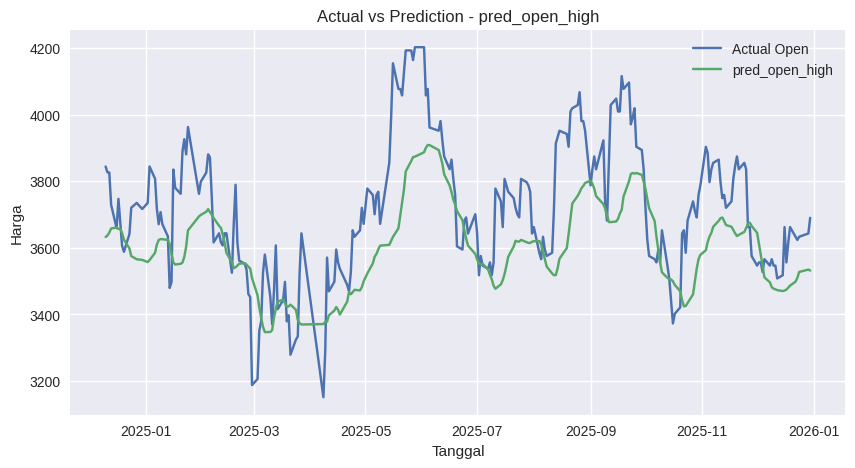

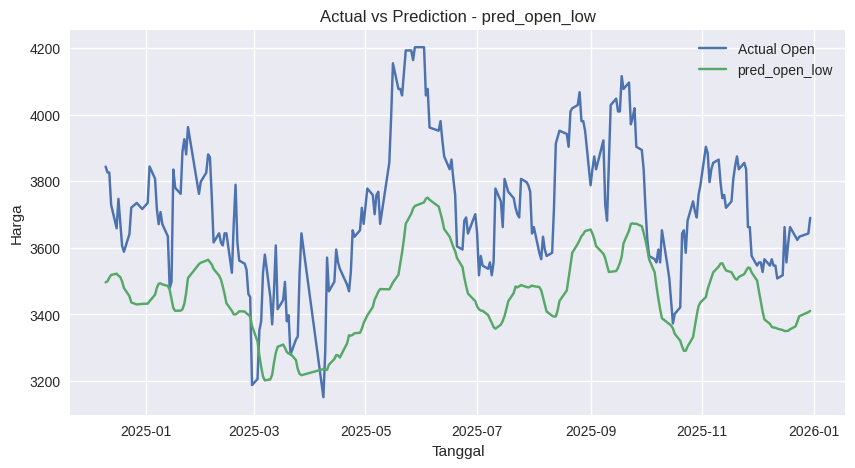

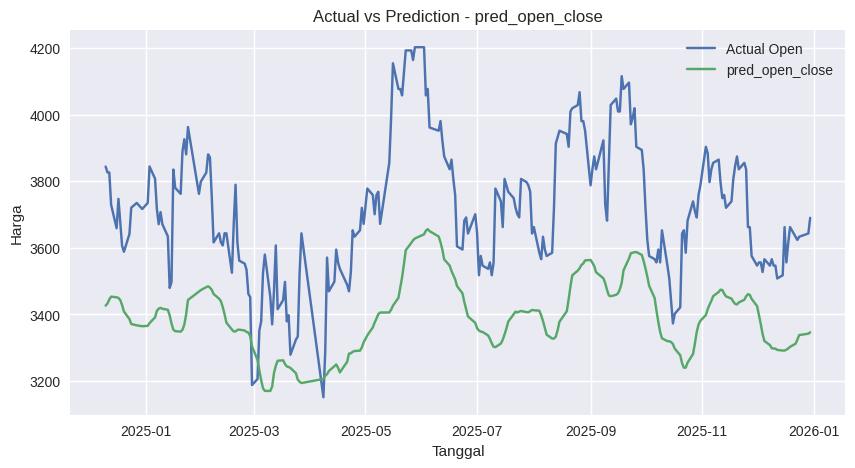

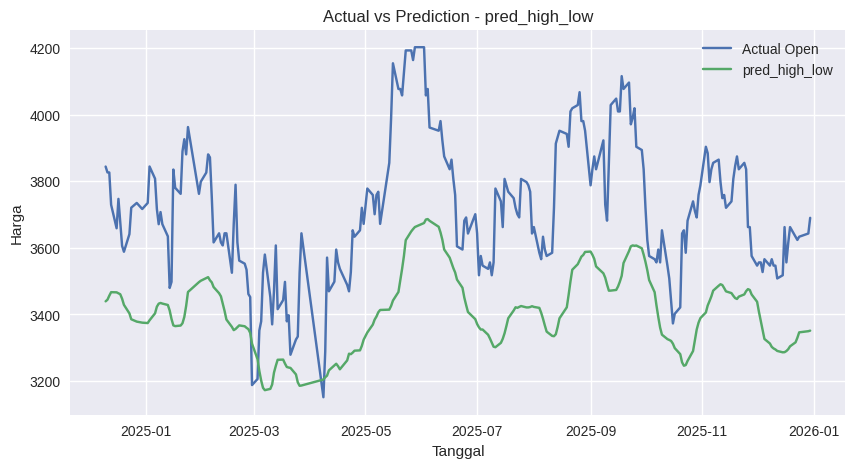

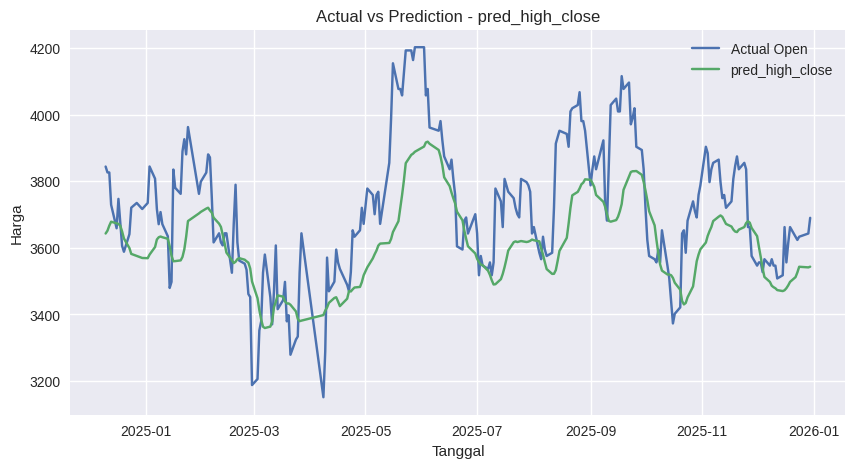

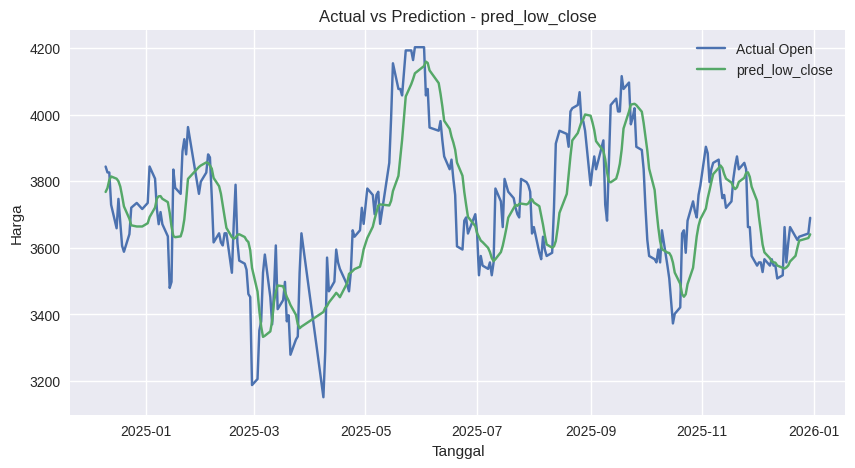

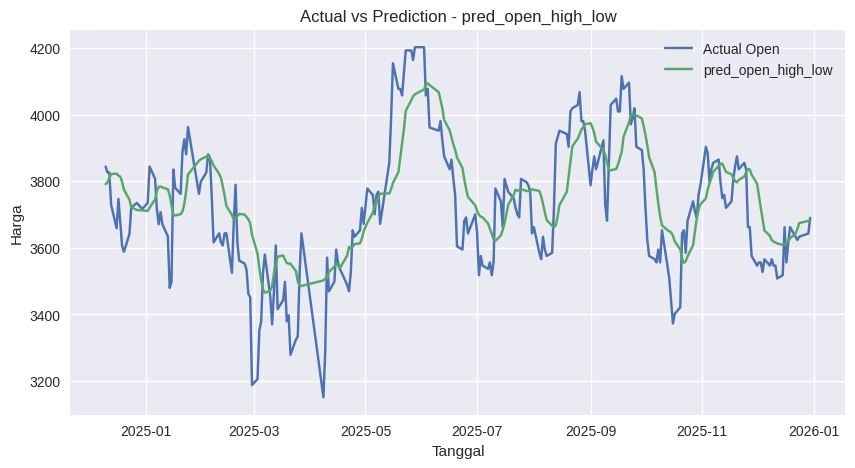

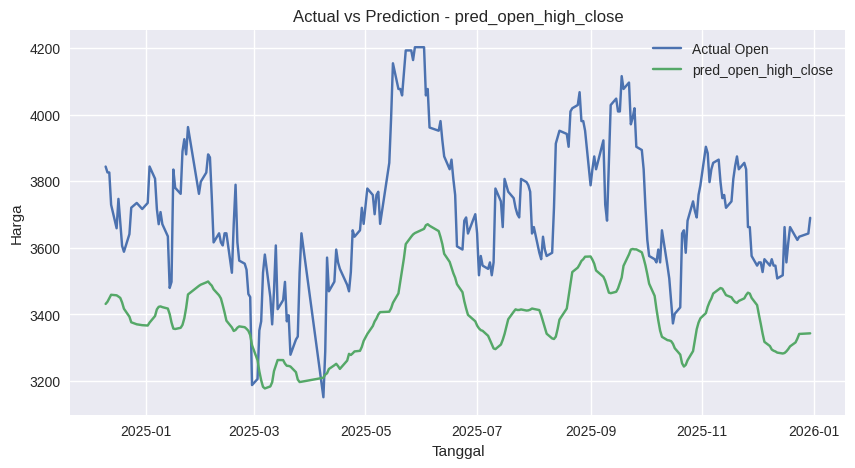

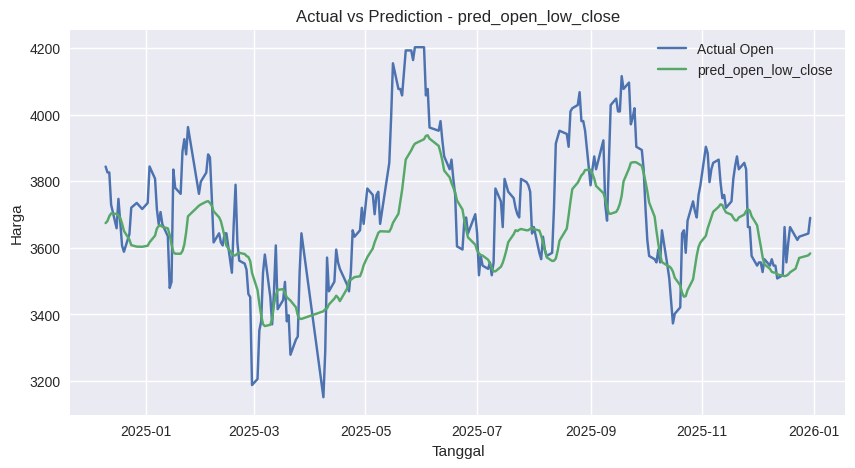

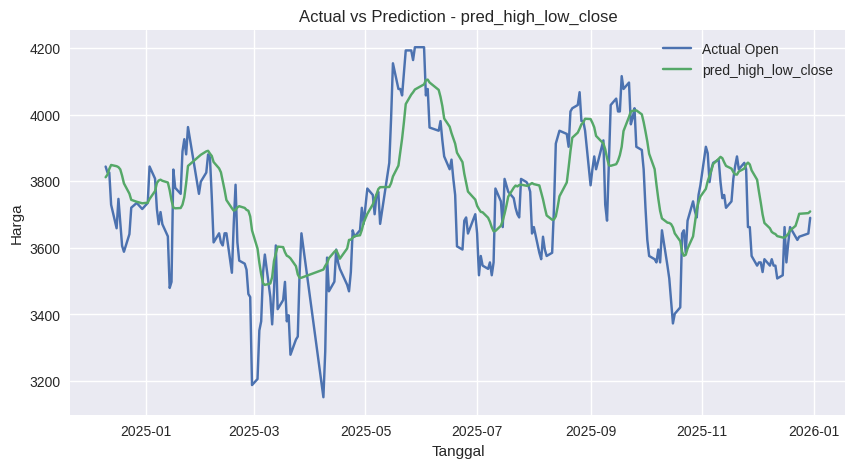

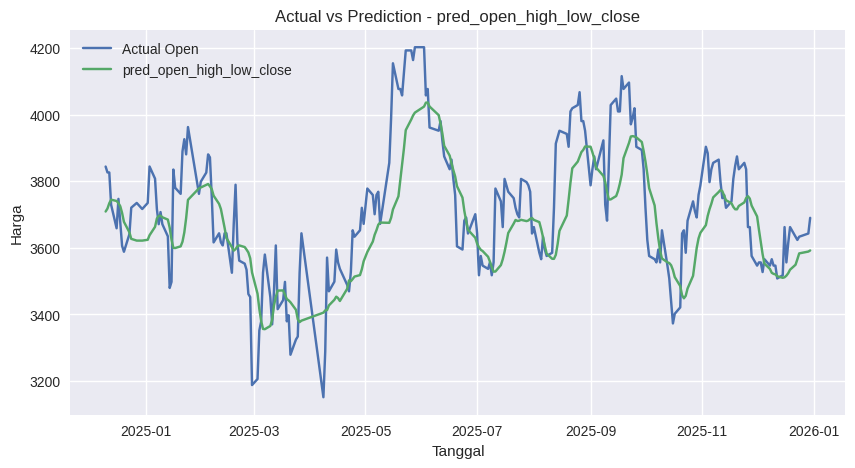

In [ ]:
#GANTI
import matplotlib.pyplot as plt

for col in prediction_columns:
    plt.style.use("seaborn-v0_8")
    plt.figure(figsize=(10,5))

    plt.plot(results_df["date"], results_df["actual_open"], label="Actual Open")
    plt.plot(results_df["date"], results_df[col], label=col)

    plt.title(f"Actual vs Prediction - {col}")
    plt.xlabel("Tanggal")
    plt.ylabel("Harga")

    plt.legend()
    plt.grid(True)

    plt.show()

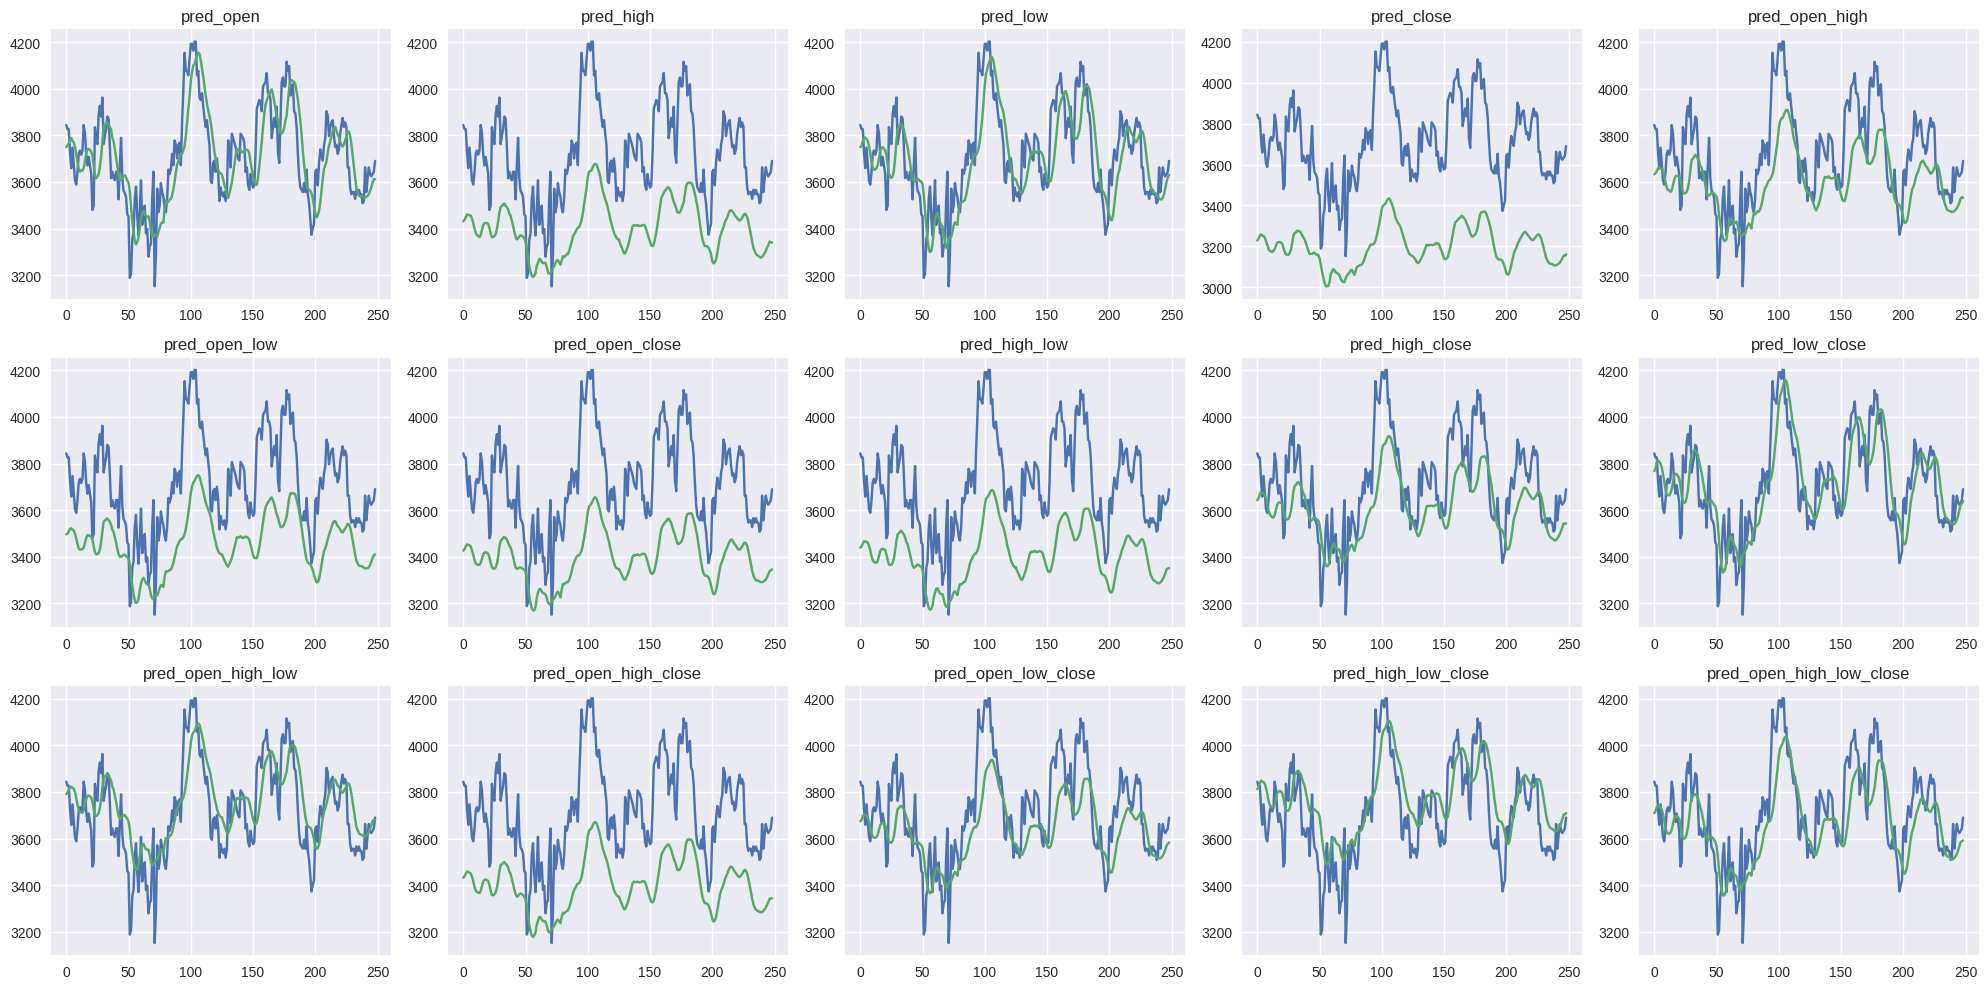

In [ ]:
#GANTI
fig, axes = plt.subplots(3,5, figsize=(20,10))
axes = axes.flatten()

for i, col in enumerate(prediction_columns):

    axes[i].plot(results_df["actual_open"], label="Actual")
    axes[i].plot(results_df[col], label="Prediksi")

    axes[i].set_title(col)
    axes[i].grid(True)

plt.style.use("seaborn-v0_8")
plt.tight_layout()
plt.show()

# MSE without DIFFERENCING

In [ ]:
prediction_columns = [
    'pred_open',
    'pred_high',
    'pred_low',
    'pred_close',
    'pred_open_high',
    'pred_open_low',
    'pred_open_close',
    'pred_high_low',
    'pred_high_close',
    'pred_low_close',
    'pred_open_high_low',
    'pred_open_high_close',
    'pred_open_low_close',
    'pred_high_low_close',
    'pred_open_high_low_close'
]

In [ ]:
#GANTI
import numpy as np
import pandas as pd

# Error setiap model
for col in prediction_columns:

    error_col = "error_" + col

    results_df[error_col] = (results_df["actual_open"] - results_df[col])**2


# MSE dan RMSE setiap model
evaluation_results = []

for col in prediction_columns:

    error_col = "error_" + col

    mse = results_df[error_col].mean()
    rmse = np.sqrt(mse)

    evaluation_results.append([col, mse, rmse])


# Membuat tabel evaluasi
tabel_evaluasi = pd.DataFrame(evaluation_results, columns=["Model", "MSE", "RMSE"])

print(tabel_evaluasi)

                       Model            MSE        RMSE
0                  pred_open   18379.752640  135.571946
1                  pred_high  114823.769835  338.856562
2                   pred_low   18380.633495  135.575195
3                 pred_close  283764.832464  532.695816
4             pred_open_high   31483.537257  177.436009
5              pred_open_low   82285.195042  286.853961
6            pred_open_close  120490.729491  347.117746
7              pred_high_low  112238.488310  335.020131
8            pred_high_close   28198.362484  167.923681
9             pred_low_close   15737.763078  125.450241
10        pred_open_high_low   18467.822950  135.896368
11      pred_open_high_close  116298.635473  341.025857
12       pred_open_low_close   23433.059162  153.078605
13       pred_high_low_close   19998.093383  141.414615
14  pred_open_high_low_close   18253.543632  135.105676


In [ ]:
# Urutan model terbaik berdasarkan MSE

tabel_evaluasi = tabel_evaluasi.sort_values(by="MSE")
print(tabel_evaluasi)

                       Model            MSE        RMSE
9             pred_low_close   15737.763078  125.450241
14  pred_open_high_low_close   18253.543632  135.105676
0                  pred_open   18379.752640  135.571946
2                   pred_low   18380.633495  135.575195
10        pred_open_high_low   18467.822950  135.896368
13       pred_high_low_close   19998.093383  141.414615
12       pred_open_low_close   23433.059162  153.078605
8            pred_high_close   28198.362484  167.923681
4             pred_open_high   31483.537257  177.436009
5              pred_open_low   82285.195042  286.853961
7              pred_high_low  112238.488310  335.020131
1                  pred_high  114823.769835  338.856562
11      pred_open_high_close  116298.635473  341.025857
6            pred_open_close  120490.729491  347.117746
3                 pred_close  283764.832464  532.695816


# PREDIKSI 7 HARI KE DEPAN

In [ ]:
#GANTI
last_sequence = X_test_open[-1]
last_sequence

array([[0.74436283],
       [0.75840786],
       [0.76994148],
       [0.76303964],
       [0.76072686],
       [0.76303967],
       [0.76534633]])

In [ ]:
#GANTI
future_predictions = []

current_sequence = last_sequence.copy()

for i in range(8):

    pred = models["open"].predict(current_sequence.reshape(1, current_sequence.shape[0], current_sequence.shape[1]))

    future_predictions.append(pred[0,0])

    # update window
    current_sequence = np.roll(current_sequence, -1, axis=0)

    # masukkan prediksi ke timestep terakhir
    current_sequence[-1, 0] = pred

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step


/tmp/ipykernel_2460/1529551275.py:16: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  current_sequence[-1, 0] = pred


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step


In [ ]:
#GANTI
future_predictions = np.array(future_predictions).reshape(-1,1)

# inverse scaler
future_log = scaler_open.inverse_transform(future_predictions)

# inverse log
future_prices = np.exp(future_log)

future_prices = future_prices.flatten()

In [ ]:
print("Prediksi harga saham 7 hari ke depan:")

for i, price in enumerate(future_prices, start=1):
    print(f"Hari ke-{i}: {price:.2f}")

Prediksi harga saham 7 hari ke depan:
Hari ke-1: 3610.75
Hari ke-2: 3620.17
Hari ke-3: 3620.42
Hari ke-4: 3614.33
Hari ke-5: 3611.68
Hari ke-6: 3609.73
Hari ke-7: 3606.19
Hari ke-8: 3601.31
